# Regression and forecasting

Reproduce the two Figure 4 tasks with a reservoir-type ONN: power-plant output
regression (CCPP) and autonomous NARMA10 forecasting. 
Run `Exp_an.ipynb` to reconstruct the experimental results from camera data.



In [1]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from utils.reservoir_onn import set_seed, tm_ensemble
from utils.datasets import load_npz, save_npz
from utils.regression import (preprocess_ccpp, query_feature_cache, distill_regression,
    evaluate_regression, raw_regression_metrics, random_support_indices,
    search_random_lambda, search_full_lambda)
from utils.forecasting import (preprocess_narma10, quantize_mask, ReservoirReadoutEnsemble,
    autonomous_rollout, r2_per_tm)
from utils.regression_plotting import (result_table, regression_sweep,
    regression_scatter, forecasting_trajectory)

get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = Path.cwd()
EXPERIMENT = ROOT / 'results/experimental'
RERUN = ROOT / 'results/simulation/regression'
FIGURES = ROOT / 'results/simulation/regression/figures'
flat_result_directory(RERUN).mkdir(parents=True, exist_ok=True)
flat_result_directory(FIGURES).mkdir(parents=True, exist_ok=True)

SEARCH_LAMBDA = False
SAVE_FIGURES = False  # Figures remain visible; enable to export files.
DEVICE = 'cuda:1' if torch.cuda.device_count() > 1 else ('cuda:0' if torch.cuda.is_available() else 'cpu')
REPETITIONS = 5
LAMBDA_GRID = [.001, .01, .1, 1., 10., 100.]
OPTIMIZATION = dict(batch_size=128, tms_per_step=1, lr_x=.02, lr_y=.01, gradient_clip=10.)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'pdf.fonttype': 42, 'ps.fonttype': 42, 'figure.dpi': 120})

def show_panel(figure, name):
    if SAVE_FIGURES:
        figure.savefig(flat_result_path(FIGURES / f'{name}.pdf'), bbox_inches='tight')
        figure.savefig(flat_result_path(FIGURES / f'{name}.png'), dpi=220, bbox_inches='tight')
    plt.show()


## Power plant output regression


In [2]:
CCPP_SIZES = [2, 4, 8, 12, 16, 24, 32]
CCPP_BASE_SEED = 20260821
ccpp_selection = {'support_sizes': [2, 4, 8, 12, 16, 24, 32],
 'coreset': [[0.01, 1.0, 0.001, 0.1, 0.01, 0.001, 0.001],
             [1.0, 1.0, 0.1, 0.001, 0.01, 0.01, 0.1],
             [0.1, 0.1, 1.0, 0.1, 0.01, 0.1, 0.01],
             [0.1, 0.001, 0.1, 0.001, 0.01, 0.1, 0.001],
             [0.1, 0.001, 1.0, 0.01, 0.1, 0.01, 0.01]],
 'random': [[0.001, 0.001, 0.1, 1.0, 1.0, 1.0, 1.0],
            [100.0, 1.0, 0.1, 1.0, 1.0, 1.0, 1.0],
            [100.0, 0.001, 1.0, 1.0, 1.0, 1.0, 1.0],
            [0.001, 0.001, 1.0, 1.0, 1.0, 1.0, 1.0],
            [0.001, 0.001, 1.0, 1.0, 1.0, 1.0, 1.0]],
 'full': [0.01, 0.01, 0.01, 0.01, 0.01]}
assert ccpp_selection['support_sizes'] == CCPP_SIZES
ccpp_data = [preprocess_ccpp(ROOT / 'dataset/CCPP' / 'Folds5x2_pp.xlsx',
    device=DEVICE, split_seed=CCPP_BASE_SEED + 100 * rep, projection_seed=20330821)
    for rep in range(REPETITIONS)]


In [3]:
coreset_r2 = np.empty((REPETITIONS, len(CCPP_SIZES), 50))
random_r2 = np.empty_like(coreset_r2)
full_r2 = np.empty((REPETITIONS, 50))
for rep, data in enumerate(ccpp_data):
    seed_root = CCPP_BASE_SEED + 100000 + 10000 * rep
    set_seed(seed_root)
    train_seeds = np.arange(seed_root + 1000, seed_root + 1050)
    validation_seeds = np.arange(seed_root + 5000, seed_root + 5010)
    test_seeds = np.arange(seed_root + 9000, seed_root + 9050)
    train_tms = tm_ensemble(64, 1024, train_seeds, DEVICE)
    validation_tms = tm_ensemble(64, 1024, validation_seeds, DEVICE)
    test_tms = tm_ensemble(64, 1024, test_seeds, DEVICE)
    validation_cache = query_feature_cache(data['x_val_select'], validation_tms)
    test_cache = query_feature_cache(data['x_test'], test_tms)
    record = dict(train_tm_seeds=train_seeds, validation_tm_seeds=validation_seeds,
                  test_tm_seeds=test_seeds)

    if SEARCH_LAMBDA:
        full_search = search_full_lambda(data, LAMBDA_GRID, validation_tms,
                                         validation_cache=validation_cache)
        random_search = search_random_lambda(data, CCPP_SIZES, LAMBDA_GRID,
            validation_tms, draws=5, seed=CCPP_BASE_SEED + 200000 + 10000 * rep,
            validation_cache=validation_cache)
        ccpp_selection['full'][rep] = full_search['best_lambda']
        ccpp_selection['random'][rep] = random_search['best_lambda'].tolist()
        record['full_lambda_scores'] = full_search['scores']
        record['random_lambda_scores'] = random_search['scores']

    full = evaluate_regression(torch.cat([data['x_train'], data['x_val']]),
        torch.cat([data['y_train'], data['y_val']]), data['x_test'], data['y_test'],
        test_tms, ccpp_selection['full'][rep], query_cache=test_cache, return_predictions=True)
    full_r2[rep] = raw_regression_metrics(full['prediction_per_tm'], data)['r2']
    for column, size in enumerate(CCPP_SIZES):
        if SEARCH_LAMBDA:
            scores = []
            for ridge_lambda in LAMBDA_GRID:
                pilot = distill_regression(data, support_size=size, ridge_lambda=ridge_lambda,
                    train_tms=train_tms, validation_tms=validation_tms, steps=100,
                    seed=CCPP_BASE_SEED + 300000 + 10000 * rep + 100 * size,
                    eval_every=50, validation_cache=validation_cache, **OPTIMIZATION)
                scores.append(pilot.best_validation_r2)
            ccpp_selection['coreset'][rep][column] = LAMBDA_GRID[int(np.argmax(scores))]
            record[f'size{size}_lambda_scores'] = np.asarray(scores)
        core_lambda = ccpp_selection['coreset'][rep][column]
        distilled = distill_regression(data, support_size=size, ridge_lambda=core_lambda,
            train_tms=train_tms, validation_tms=validation_tms, steps=600,
            seed=CCPP_BASE_SEED + 500000 + 10000 * rep + 100 * size,
            eval_every=100, validation_cache=validation_cache, **OPTIMIZATION)
        core = evaluate_regression(distilled.x_distilled, distilled.y_distilled,
            data['x_test'], data['y_test'], test_tms, core_lambda,
            query_cache=test_cache, return_predictions=True)
        coreset_r2[rep, column] = raw_regression_metrics(core['prediction_per_tm'], data)['r2']

        indices = random_support_indices(len(data['x_train']), size,
            CCPP_BASE_SEED + 600000 + 10000 * rep + 100 * size, DEVICE)
        random = evaluate_regression(data['x_train'][indices], data['y_train'][indices],
            data['x_test'], data['y_test'], test_tms, ccpp_selection['random'][rep][column],
            query_cache=test_cache, return_predictions=True)
        random_r2[rep, column] = raw_regression_metrics(random['prediction_per_tm'], data)['r2']
        for name in ['x_init', 'x_distilled', 'y_init', 'y_distilled',
                     'latent_x_init', 'latent_x_distilled', 'source_indices']:
            record[f'size{size}_{name}'] = getattr(distilled, name).detach().cpu().numpy()
        for name in ['loss_history', 'validation_steps', 'validation_r2',
                     'best_step', 'best_validation_r2']:
            record[f'size{size}_{name}'] = np.asarray(getattr(distilled, name))
        record[f'size{size}_random_indices'] = indices.cpu().numpy()
    save_npz(RERUN / f'ccpp_rep{rep}.npz', record)
    del train_tms, validation_tms, test_tms, validation_cache, test_cache
    torch.cuda.empty_cache()
ccpp_simulation = dict(support_sizes=np.asarray(CCPP_SIZES),
    coreset_r2=coreset_r2.mean(axis=2), random_r2=random_r2.mean(axis=2), full_r2=full_r2.mean(),
    coreset_r2_per_tm=coreset_r2, random_r2_per_tm=random_r2, full_r2_per_tm=full_r2)
save_npz(RERUN / 'ccpp.npz', ccpp_simulation)
(flat_result_path(RERUN / 'ccpp_lambda.json')).write_text(json.dumps(ccpp_selection, indent=2))
print('CCPP complete')


CCPP complete


### Test R² versus training-set size

Entries and error bars report mean ± sample standard deviation. Simulation has
five repetitions; experiment has ten measured repetitions. The y-axis is
compressed below R² = 0.4 by a factor of 0.24, with a transition mark on the spine.


,Coreset (sim.),Random (sim.),Coreset (exp.),Random (exp.)
Training samples,,,,
2,0.895 ± 0.006,0.320 ± 0.274,0.897 ± 0.007,0.284 ± 0.242
4,0.902 ± 0.004,0.433 ± 0.441,0.901 ± 0.005,0.403 ± 0.453
8,0.916 ± 0.003,0.760 ± 0.053,0.916 ± 0.004,0.763 ± 0.062
12,0.931 ± 0.002,0.819 ± 0.049,0.931 ± 0.002,0.816 ± 0.052
16,0.934 ± 0.003,0.838 ± 0.033,0.932 ± 0.003,0.841 ± 0.032
24,0.937 ± 0.003,0.869 ± 0.032,0.935 ± 0.004,0.872 ± 0.030
32,0.938 ± 0.002,0.897 ± 0.020,0.936 ± 0.006,0.898 ± 0.020


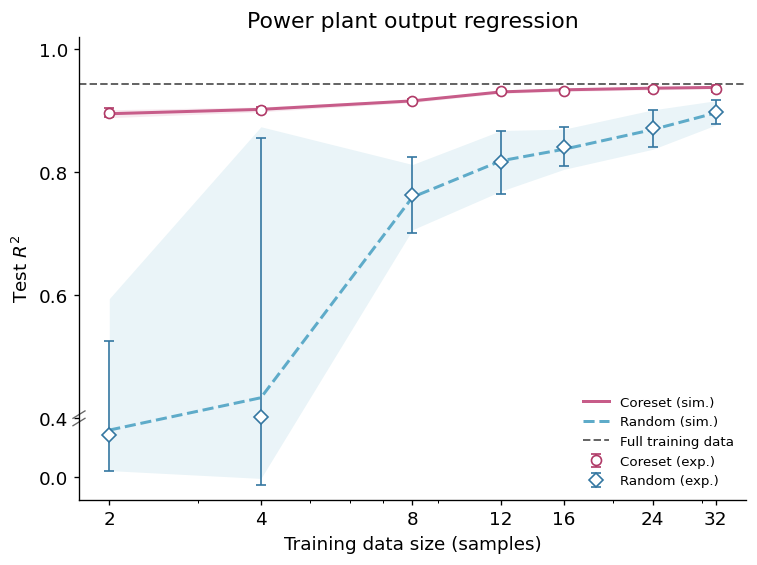

In [4]:
ccpp_experiment = load_npz(EXPERIMENT / 'ccpp_experiment.npz')
display(result_table(ccpp_simulation, ccpp_experiment))
show_panel(regression_sweep(ccpp_simulation, ccpp_experiment,
    title='Power plant output regression', task='ccpp'), 'ccpp_sweep')


### Experimental predictions using two training samples

The fixed example is acquisition 2, repetition 5. R² uses all 1,906 test
observations. These camera-derived predictions are reconstructed in `Exp_an.ipynb`.


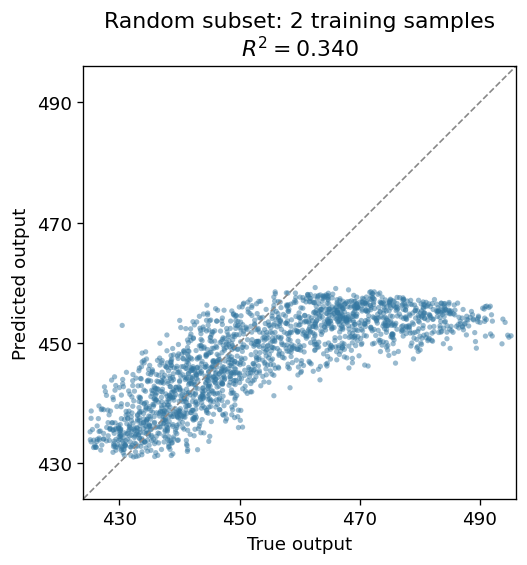

In [5]:
show_panel(regression_scatter(ccpp_experiment['selected_truth'],
    ccpp_experiment['selected_random'], method='Random subset'), 'ccpp_random_scatter')


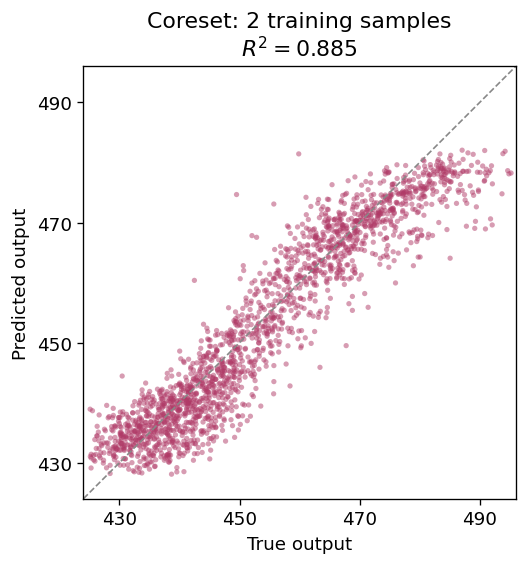

In [6]:
show_panel(regression_scatter(ccpp_experiment['selected_truth'],
    ccpp_experiment['selected_coreset'], method='Coreset'), 'ccpp_coreset_scatter')


## Autonomous NARMA10 forecasting



In [7]:
QUANTIZE_INPUTS = True
NARMA_PRECISION = '8bit' if QUANTIZE_INPUTS else 'continuous'
NARMA_EVALUATION = RERUN / 'narma10_independent' / NARMA_PRECISION

def input_mask(x):
    return quantize_mask(x) if QUANTIZE_INPUTS else x

NARMA_SIZES = [4, 8, 12, 16, 24, 32, 48, 64]
NARMA_CONFIG = dict(washout=100, train_origins=6000, validation_origins=1200,
    test_origins=1500, base_seed=20260823, validation_limit=512,
    optical_dim=64, projection_seed=20260864)
narma_selection = {'support_sizes': [4, 8, 12, 16, 24, 32, 48, 64],
 'coreset': [[0.1, 0.01, 0.1, 0.1, 0.1, 0.01, 0.001, 0.001],
             [0.1, 0.1, 0.001, 0.001, 0.1, 0.01, 0.01, 0.001],
             [1.0, 1.0, 0.001, 0.01, 0.1, 0.1, 0.001, 0.1],
             [0.001, 0.01, 0.01, 0.1, 0.001, 0.1, 0.001, 0.001],
             [0.001, 0.1, 0.01, 0.01, 0.1, 0.001, 0.01, 0.1]],
 'random': [[100.0, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001],
            [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001],
            [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001],
            [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001],
            [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]],
 'full': [0.001, 0.001, 0.001, 0.01, 0.01]}
assert narma_selection['support_sizes'] == NARMA_SIZES
narma_data, narma_raw, drive, state, test_start = preprocess_narma10(NARMA_CONFIG, DEVICE)


In [8]:
data = narma_data
truth = state[test_start+1:test_start+201]
flat_result_directory(NARMA_EVALUATION).mkdir(parents=True, exist_ok=True)
coreset_per_tm = np.empty((REPETITIONS, len(NARMA_SIZES), 50))
random_per_tm = np.empty_like(coreset_per_tm)
full_per_tm = np.empty((REPETITIONS, 50))
for rep in range(REPETITIONS):
    seed_root = NARMA_CONFIG['base_seed'] + 100000 * rep
    set_seed(seed_root)
    train_seeds = np.arange(seed_root+1000, seed_root+1050)
    validation_seeds = np.arange(seed_root+2000, seed_root+2010)
    test_seeds = np.arange(seed_root+3000, seed_root+3050)
    test_tms = tm_ensemble(64, 1024, test_seeds, DEVICE)
    train_tms = tm_ensemble(64, 1024, train_seeds, DEVICE)
    validation_tms = tm_ensemble(64, 1024, validation_seeds, DEVICE)
    validation_cache = query_feature_cache(data['x_val_select'], validation_tms)
    support_record = dict(train_tm_seeds=train_seeds, validation_tm_seeds=validation_seeds,
                          test_tm_seeds=test_seeds, autonomous_truth=truth)
    record = dict(test_tm_seeds=test_seeds, autonomous_truth=truth,
                  test_origin=np.asarray(test_start),
                  input_precision=np.asarray(NARMA_PRECISION), evaluation_protocol=np.asarray('independent_tm_feedback'))
    if SEARCH_LAMBDA:
        full_search = search_full_lambda(data, LAMBDA_GRID, validation_tms,
                                         validation_cache=validation_cache)
        random_search = search_random_lambda(data, NARMA_SIZES, LAMBDA_GRID,
            validation_tms, draws=5, seed=seed_root+4000, validation_cache=validation_cache)
        narma_selection['full'][rep] = full_search['best_lambda']
        narma_selection['random'][rep] = random_search['best_lambda'].tolist()
        record['full_lambda_scores'] = full_search['scores']
        record['random_lambda_scores'] = random_search['scores']
    full_model = ReservoirReadoutEnsemble(input_mask(data['x_train']), data['y_train'],
                                          narma_selection['full'][rep], test_tms)
    full_prediction = autonomous_rollout(full_model, drive, state, test_start, 200,
                                         data, quantize8=QUANTIZE_INPUTS)
    full_per_tm[rep] = r2_per_tm(full_prediction, truth)
    record['full_prediction_per_tm'] = full_prediction
    record['full_r2_per_tm'] = full_per_tm[rep]
    del full_model
    for column, size in enumerate(NARMA_SIZES):
        if SEARCH_LAMBDA:
            scores = []
            for index, ridge_lambda in enumerate(LAMBDA_GRID):
                pilot = distill_regression(data, support_size=size, ridge_lambda=ridge_lambda,
                    train_tms=train_tms, validation_tms=validation_tms, steps=100,
                    seed=seed_root+5000+100*size+index, eval_every=100,
                    validation_cache=validation_cache, **OPTIMIZATION)
                scores.append(pilot.best_validation_r2)
            narma_selection['coreset'][rep][column] = LAMBDA_GRID[int(np.argmax(scores))]
            record[f'size{size}_lambda_scores'] = np.asarray(scores)
        core_lambda = narma_selection['coreset'][rep][column]
        distilled = distill_regression(data, support_size=size, ridge_lambda=core_lambda,
            train_tms=train_tms, validation_tms=validation_tms, steps=800,
            seed=seed_root+6000+100*size, eval_every=50,
            validation_cache=validation_cache, **OPTIMIZATION)
        for name in ['x_init', 'x_distilled', 'y_init', 'y_distilled',
                     'latent_x_init', 'latent_x_distilled', 'source_indices']:
            support_record[f'size{size}_{name}'] = getattr(distilled, name).detach().cpu().numpy()
        for name in ['loss_history', 'validation_steps', 'validation_r2',
                     'best_step', 'best_validation_r2']:
            support_record[f'size{size}_{name}'] = np.asarray(getattr(distilled, name))
        indices = random_support_indices(len(data['x_train']), size,
                                         seed_root+7000+100*size, DEVICE)
        support_record[f'size{size}_random_indices'] = indices.cpu().numpy()
        core_lambda = narma_selection['coreset'][rep][column]
        core_x = torch.as_tensor(support_record[f'size{size}_x_distilled'], device=DEVICE)
        core_y = torch.as_tensor(support_record[f'size{size}_y_distilled'], device=DEVICE)
        indices = torch.as_tensor(support_record[f'size{size}_random_indices'],
                                  dtype=torch.long, device=DEVICE)
        core_model = ReservoirReadoutEnsemble(input_mask(core_x), core_y, core_lambda, test_tms)
        core_prediction = autonomous_rollout(core_model, drive, state, test_start, 200,
                                             data, quantize8=QUANTIZE_INPUTS)
        coreset_per_tm[rep, column] = r2_per_tm(core_prediction, truth)
        random_model = ReservoirReadoutEnsemble(input_mask(data['x_train'][indices]), data['y_train'][indices],
                                                narma_selection['random'][rep][column], test_tms)
        random_prediction = autonomous_rollout(random_model, drive, state, test_start, 200, data, quantize8=QUANTIZE_INPUTS)
        random_per_tm[rep, column] = r2_per_tm(random_prediction, truth)
        record[f'size{size}_coreset_prediction_per_tm'] = core_prediction
        record[f'size{size}_random_prediction_per_tm'] = random_prediction
        record[f'size{size}_coreset_r2_per_tm'] = coreset_per_tm[rep, column]
        record[f'size{size}_random_r2_per_tm'] = random_per_tm[rep, column]
        del core_model, random_model
    save_npz(NARMA_EVALUATION / f'rep{rep}.npz', record)
    support_record.update(full_lambda=np.asarray(narma_selection['full'][rep]),
                          coreset_lambda=np.asarray(narma_selection['coreset'][rep]),
                          random_lambda=np.asarray(narma_selection['random'][rep]))
    save_npz(RERUN / f'narma10_rep{rep}.npz', support_record)
    del train_tms, validation_tms, validation_cache
    del test_tms
    torch.cuda.empty_cache()
narma_simulation = dict(
    support_sizes=np.asarray(NARMA_SIZES),
    coreset_r2=coreset_per_tm.mean(axis=2), random_r2=random_per_tm.mean(axis=2),
    full_r2=np.asarray(full_per_tm.mean()), full_r2_per_rep=full_per_tm.mean(axis=1),
    coreset_r2_per_tm=coreset_per_tm, random_r2_per_tm=random_per_tm,
    full_r2_per_tm=full_per_tm, input_precision=np.asarray(NARMA_PRECISION), evaluation_protocol=np.asarray('independent_tm_feedback'))
save_npz(NARMA_EVALUATION / 'summary.npz', narma_simulation)
(flat_result_path(NARMA_EVALUATION / 'lambda.json')).write_text(json.dumps(narma_selection, indent=2))
print('NARMA10 complete')


NARMA10 complete


### Autonomous test R² versus training-set size

Entries and error bars use the repetition-level statistics defined above.
The y-axis is compressed below R² = 0 by a factor of 0.18, with a transition mark.


,Coreset (sim.),Random (sim.),Coreset (exp.),Random (exp.)
Training samples,,,,
4,0.742 ± 0.039,-0.437 ± 0.322,0.693 ± 0.119,-0.717 ± 0.950
8,0.817 ± 0.012,0.124 ± 0.470,0.721 ± 0.084,0.270 ± 0.371
12,0.845 ± 0.017,0.366 ± 0.209,0.759 ± 0.127,0.164 ± 0.569
16,0.858 ± 0.012,0.334 ± 0.213,0.812 ± 0.067,0.327 ± 0.263
24,0.881 ± 0.012,0.532 ± 0.166,0.857 ± 0.035,0.583 ± 0.192
32,0.910 ± 0.005,0.480 ± 0.147,0.841 ± 0.070,0.568 ± 0.249
48,0.914 ± 0.011,0.700 ± 0.111,0.873 ± 0.045,0.783 ± 0.044
64,0.918 ± 0.007,0.754 ± 0.067,0.911 ± 0.021,0.730 ± 0.084


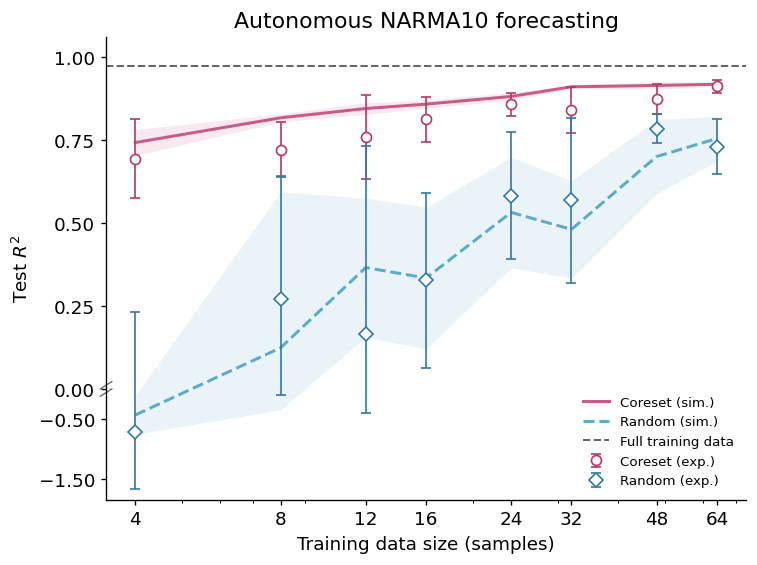

In [9]:
narma_experiment = load_npz(EXPERIMENT / 'narma10_experiment.npz')
display(result_table(narma_simulation, narma_experiment))
show_panel(regression_sweep(narma_simulation, narma_experiment,
    title='Autonomous NARMA10 forecasting', task='narma10'), f'narma10_sweep_{NARMA_PRECISION}')


### Experimental predicted trajectories using 12 training samples



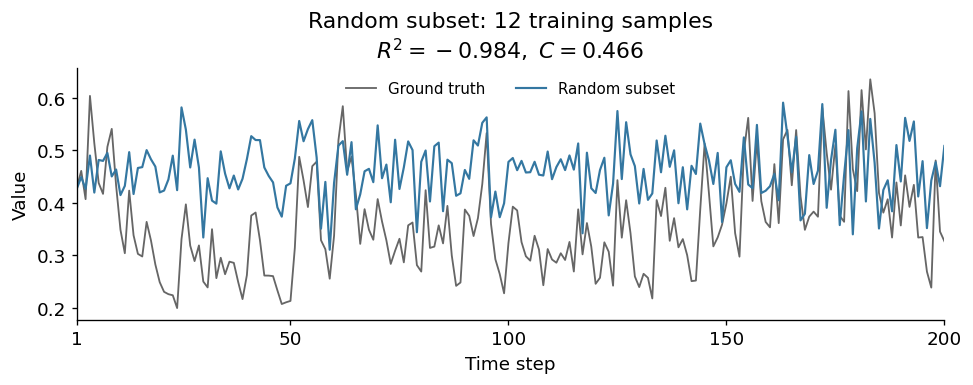

In [10]:
show_panel(forecasting_trajectory(narma_experiment['selected_truth'],
    narma_experiment['selected_random'], method='Random subset'), 'narma10_random_trajectory')


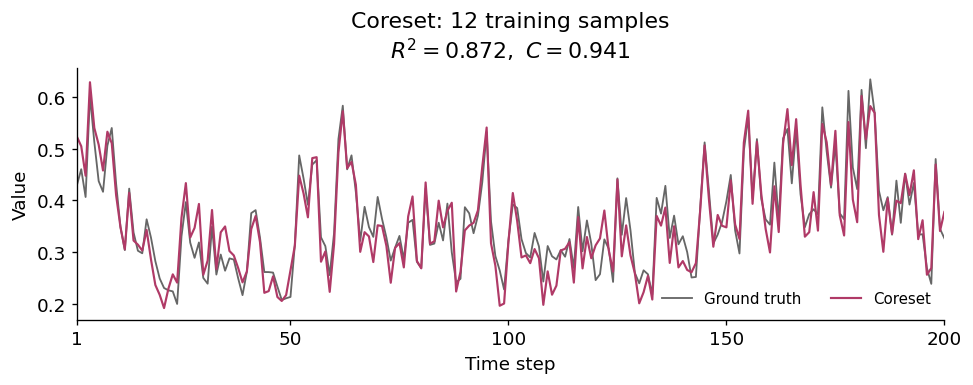

In [11]:
show_panel(forecasting_trajectory(narma_experiment['selected_truth'],
    narma_experiment['selected_coreset'], method='Coreset'), 'narma10_coreset_trajectory')
